# Régression linéaire : prédiction de la demande de vélos à Séoul

Le sujet, les données et leur preprocessing, les deux protocoles (daily et temporal) et les métriques sont présentés dans `introduction.ipynb`. Ce notebook teste la famille des régressions linéaires.

## 1. L'algorithme : la régression linéaire

La régression linéaire prédit la cible comme une **somme pondérée des variables** :

$$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b$$

- $x_1, \dots, x_n$ : les variables (température, heure…) ;
- $w_1, \dots, w_n$ : les **poids**, qui disent combien chaque variable fait varier la demande ;
- $b$ : le **biais**, la valeur de départ.

**Entraînement** : l'algorithme cherche les poids $w$ et $b$ qui minimisent l'**erreur quadratique moyenne** sur les données d'entraînement :

$$J(w, b) = \frac{1}{m} \sum_{i=1}^{m} \left(\hat{y}^{(i)} - y^{(i)}\right)^2$$

Dans scikit-learn, c'est `LinearRegression()`.

**Démarche** : on part du modèle le plus simple possible, puis on le **complexifie petit à petit**, en vérifiant à chaque étape que l'erreur baisse.

## 2. Chargement des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from decoupage import charger_donnees, decoupage_daily, cv_daily, decoupage_temporal, cv_temporal, variables, CIBLE

# Découpage daily
df_brut = charger_donnees()
train, test = decoupage_daily(df_brut)
TARGET = CIBLE
FEATURES = variables(train)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

# Découpage temporal
train_temporal, test_temporal = decoupage_temporal(df_brut)
X_train_temporal, y_train_temporal = train_temporal[FEATURES], train_temporal[TARGET]
X_test_temporal, y_test_temporal = test_temporal[FEATURES], test_temporal[TARGET]

print(f"[DAILY]    Entraînement : {train['date'].nunique()} jours ({len(train)} h) | Test : {test['date'].nunique()} jours ({len(test)} h)")
print(f"[TEMPORAL] Entraînement : {train_temporal['date'].nunique()} jours ({len(train_temporal)} h) | Test : {test_temporal['date'].nunique()} jours ({len(test_temporal)} h)")

[DAILY]    Entraînement : 283 jours (6785 h) | Test : 70 jours (1680 h)
[TEMPORAL] Entraînement : 282 jours (6768 h) | Test : 71 jours (1697 h)


## 3. Évaluation

On utilise les plis de cross-validation communs à tout le groupe (voir `introduction.ipynb`) : 5 plis de jours entiers en daily, une semaine par pli en temporal.

In [2]:
from sklearn.model_selection import cross_validate

# 5 plis de jours entiers
splits = cv_daily(train, n_splits=5)
print(f"Protocole DAILY : {len(splits)} plis")

# une semaine par pli
splits_temporal = cv_temporal(train_temporal)
print(f"Protocole TEMPORAL : {len(splits_temporal)} plis (une semaine chacun)")

Protocole DAILY : 5 plis
Protocole TEMPORAL : 23 plis (une semaine chacun)


### Fonction d'évaluation

`evaluer` lance la cross-validation d'un modèle sur les deux protocoles et ajoute une ligne au tableau des résultats (RMSE CV et R² CV, en Daily et en Temporal).

In [3]:
resultats = []

def evaluer(nom, modele, X=None):
    """Cross-validation du modèle sur les deux protocoles."""
    if X is None:
        X_d, X_t = X_train, X_train_temporal
    else:
        X_d = X
        if len(X.columns) > len(FEATURES) and "feature_engineering" in globals():
            X_t = feature_engineering(X_train_temporal)
        else:
            X_t = X_train_temporal

    # Daily
    s_d = cross_validate(
        modele, X_d, y_train, cv=splits,
        scoring={"RMSE": "neg_root_mean_squared_error", "R2": "r2"},
        return_train_score=True,
    )
    
    # Temporal
    s_t = cross_validate(
        modele, X_t, y_train_temporal, cv=splits_temporal,
        scoring={"RMSE": "neg_root_mean_squared_error", "R2": "r2"},
        return_train_score=True,
    )
    
    resultats.append({
        "Modèle": nom,
        "RMSE CV (Daily)": -s_d["test_RMSE"].mean(),
        "R² CV (Daily)": s_d["test_R2"].mean(),
        "RMSE CV (Temporal)": -s_t["test_RMSE"].mean(),
        "R² CV (Temporal)": s_t["test_R2"].mean(),
    })
    
    df_res = pd.DataFrame(resultats).set_index("Modèle")
    return df_res.round({"RMSE CV (Daily)": 1, "R² CV (Daily)": 3, "RMSE CV (Temporal)": 1, "R² CV (Temporal)": 3})

On met d'abord dans le tableau le modèle de référence (prédire toujours la moyenne) : RMSE CV de 645 vélos/h en daily et 810 en temporal.

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

evaluer("0. Moyenne (référence)", make_pipeline(StandardScaler(), DummyRegressor(strategy="mean")), X_train)

,RMSE CV (Daily),R² CV (Daily),RMSE CV (Temporal),R² CV (Temporal)
Modèle,,,,
0. Moyenne (référence),644.8,-0.002,809.7,-0.528


## 4. Modèle 1 : régression linéaire classique

On entraîne la régression linéaire de scikit-learn (`LinearRegression`) sur les **25 variables normalisées**. C'est exactement la formule de la section 1 : une somme pondérée des variables.

In [5]:
from sklearn.linear_model import LinearRegression

evaluer("1. Régression linéaire (25 variables)", make_pipeline(StandardScaler(), LinearRegression()), X_train)

,RMSE CV (Daily),R² CV (Daily),RMSE CV (Temporal),R² CV (Temporal)
Modèle,,,,
0. Moyenne (référence),644.8,-0.002,809.7,-0.528
1. Régression linéaire (25 variables),368.0,0.673,484.5,0.436


**Daily**
- Bien mieux que la référence : l'erreur passe de 645 à **368 vélos/h**, et le modèle explique **67 %** des variations de la demande (R² = 0,67).
- Mais la RMSE train (362) et la RMSE CV (368) sont **proches et élevées** : le modèle ne sur-apprend pas, il est en **sous-apprentissage** (biais élevé). Une somme pondérée des variables brutes ne suffit pas.

**Temporal**
- RMSE CV = **484,5 vélos/h**, R² = **0,436**.
- Le R² est plus bas qu'en Daily (0,44 contre 0,67) : prédire les semaines suivantes est plus difficile, surtout quand la saison change.

Biais b (DAILY)    : 725.6 vélos/h (demande moyenne : 725.6)
Biais b (TEMPORAL) : 687.6 vélos/h (demande moyenne : 687.6)


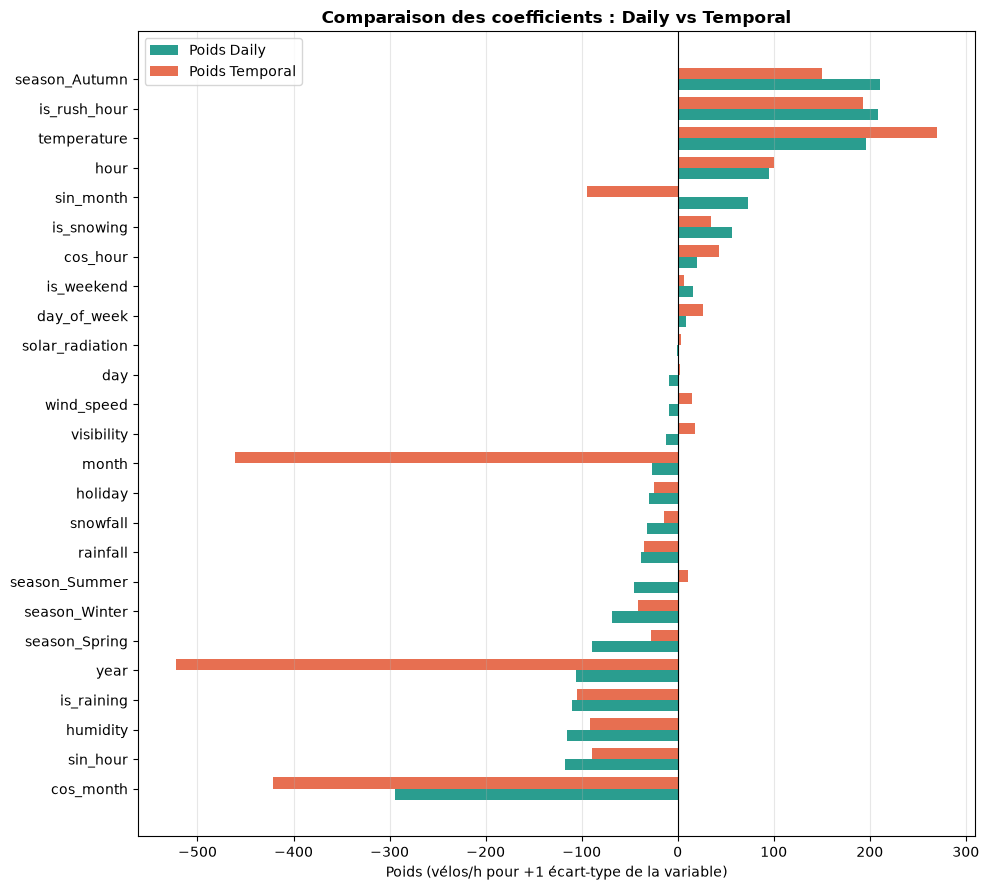

In [6]:
# Entraînement sur tout le train
modele_1_daily = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
modele_1_temporal = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train_temporal, y_train_temporal)

print(f"Biais b (DAILY)    : {modele_1_daily[-1].intercept_:.1f} vélos/h (demande moyenne : {y_train.mean():.1f})")
print(f"Biais b (TEMPORAL) : {modele_1_temporal[-1].intercept_:.1f} vélos/h (demande moyenne : {y_train_temporal.mean():.1f})")

# Comparaison des coefficients
df_coef = pd.DataFrame({
    "Daily": modele_1_daily[-1].coef_,
    "Temporal": modele_1_temporal[-1].coef_
}, index=FEATURES)
df_coef = df_coef.reindex(df_coef["Daily"].sort_values().index)

fig, ax = plt.subplots(figsize=(10, 9))
y_pos = np.arange(len(FEATURES))
height = 0.38

ax.barh(y_pos - height/2, df_coef["Daily"], height=height, label="Poids Daily", color="#2a9d8f")
ax.barh(y_pos + height/2, df_coef["Temporal"], height=height, label="Poids Temporal", color="#e76f51")
ax.set_yticks(y_pos)
ax.set_yticklabels(df_coef.index)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Poids (vélos/h pour +1 écart-type de la variable)")
ax.set_title("Comparaison des coefficients : Daily vs Temporal", fontweight="bold", fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

### Le biais $b$ et les poids $w$

Les variables sont normalisées, donc le biais $b$ est la demande moyenne du train :
- Daily : $b = 725,6$ vélos/h (moyenne sur toute l'année) ;
- Temporal : $b = 687,6$ vélos/h (moyenne de décembre au 10 septembre, l'automne est presque absent du train).

Dans la suite, les poids sont donnés sous la forme Daily / Temporal.

**Les poids de la météo et de l'heure sont proches dans les deux protocoles :**
- `is_rush_hour` (+209 / +193) et la température (+196 / +270) font partie des poids positifs les plus forts ;
- l'humidité (−115 / −91) et `is_raining` (−110 / −105) font baisser la demande.

**Les poids du calendrier sont très différents :**
- `month` : −27 / **−461** ;
- `year` : −106 / **−523**.

En Temporal, le train ne contient que des mois qui se suivent (décembre 2017 au 10 septembre 2018). Le modèle utilise `month` et `year` pour suivre la tendance de ces mois-là, ce qui ne marche plus pour l'automne.

### Où le modèle se trompe-t-il ?

Pour visualiser les erreurs, on a besoin de prédictions **honnêtes**, sur des jours que le modèle n'a pas appris. `cross_val_predict` réutilise les 5 plis de la cross-validation : chaque heure est prédite par le modèle du tour où son jour était en validation.

In [7]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

# Daily : prédictions hors pli
pred_1_daily = cross_val_predict(make_pipeline(StandardScaler(), LinearRegression()), X_train, y_train, cv=splits)
analyse_daily = train.assign(prediction=pred_1_daily)

# Temporal : cross_val_predict ne marche pas car les premiers mois ne sont jamais
# en validation, donc on fait la boucle sur les plis à la main
def predire_cv_temporal(modele, X, y, cv_splits, df_ref):
    val_indices = []
    val_predictions = []
    for tr_idx, va_idx in cv_splits:
        m = clone(modele).fit(X.iloc[tr_idx], y.iloc[tr_idx])
        val_indices.extend(va_idx)
        val_predictions.extend(m.predict(X.iloc[va_idx]))
    df_val = df_ref.iloc[val_indices].copy()
    df_val["prediction"] = val_predictions
    return df_val

analyse_temporal = predire_cv_temporal(
    make_pipeline(StandardScaler(), LinearRegression()),
    X_train_temporal, y_train_temporal, splits_temporal, train_temporal
)

#### Demande réelle et prédite selon l'heure

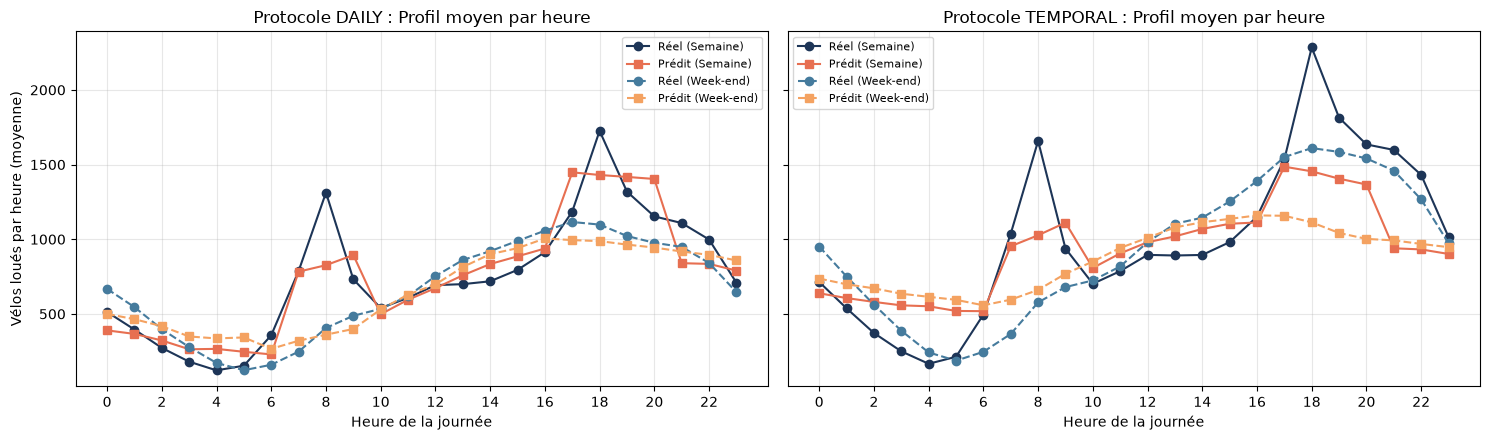

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)

# DAILY
for weekend, titre, style in [(0, "Semaine", "-"), (1, "Week-end", "--")]:
    ph = analyse_daily[analyse_daily["is_weekend"] == weekend].groupby("hour")[[TARGET, "prediction"]].mean()
    axes[0].plot(ph.index, ph[TARGET], "o" + style, color="#1d3557" if weekend==0 else "#457b9d", label=f"Réel ({titre})")
    axes[0].plot(ph.index, ph["prediction"], "s" + style, color="#e76f51" if weekend==0 else "#f4a261", label=f"Prédit ({titre})")
axes[0].set(xlabel="Heure de la journée", ylabel="Vélos loués par heure (moyenne)", xticks=range(0, 24, 2),
            title="Protocole DAILY : Profil moyen par heure")
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

# TEMPORAL
for weekend, titre, style in [(0, "Semaine", "-"), (1, "Week-end", "--")]:
    ph = analyse_temporal[analyse_temporal["is_weekend"] == weekend].groupby("hour")[[TARGET, "prediction"]].mean()
    axes[1].plot(ph.index, ph[TARGET], "o" + style, color="#1d3557" if weekend==0 else "#457b9d", label=f"Réel ({titre})")
    axes[1].plot(ph.index, ph["prediction"], "s" + style, color="#e76f51" if weekend==0 else "#f4a261", label=f"Prédit ({titre})")
axes[1].set(xlabel="Heure de la journée", xticks=range(0, 24, 2),
            title="Protocole TEMPORAL : Profil moyen par heure")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


- **En semaine**, le modèle fait des **paliers** au lieu de pics : la variable `is_rush_hour` ajoute le même nombre de vélos de 7 h à 9 h et de 17 h à 20 h en semaine. Il **sous-estime les pics** (≈ 830 vélos/h prédits à 8 h contre ≈ 1 310 en réalité, ≈ 1 430 à 18 h contre ≈ 1 730) et **surestime les heures voisines** (9 h, 20 h).
- **Le week-end**, la forme générale (une bosse l'après-midi) est assez bien suivie, mais le modèle reste trop « plat » : il surestime la nuit et sous-estime la fin d'après-midi.
- **La nuit**, il surestime dans les deux cas (≈ 270 vélos/h prédits à 4 h en semaine contre ≈ 120).

C'est la conséquence de sa forme : l'heure n'entre que par quelques variables (`hour`, `sin_hour`, `cos_hour`, `is_rush_hour`), chacune avec un effet fixe. Le modèle ne peut pas dessiner librement la courbe de la journée.

#### Réel et prédit sur une semaine complète

Semaine du lundi 25 juin au dimanche 1er juillet 2018 (tous ces jours sont dans l'entraînement).

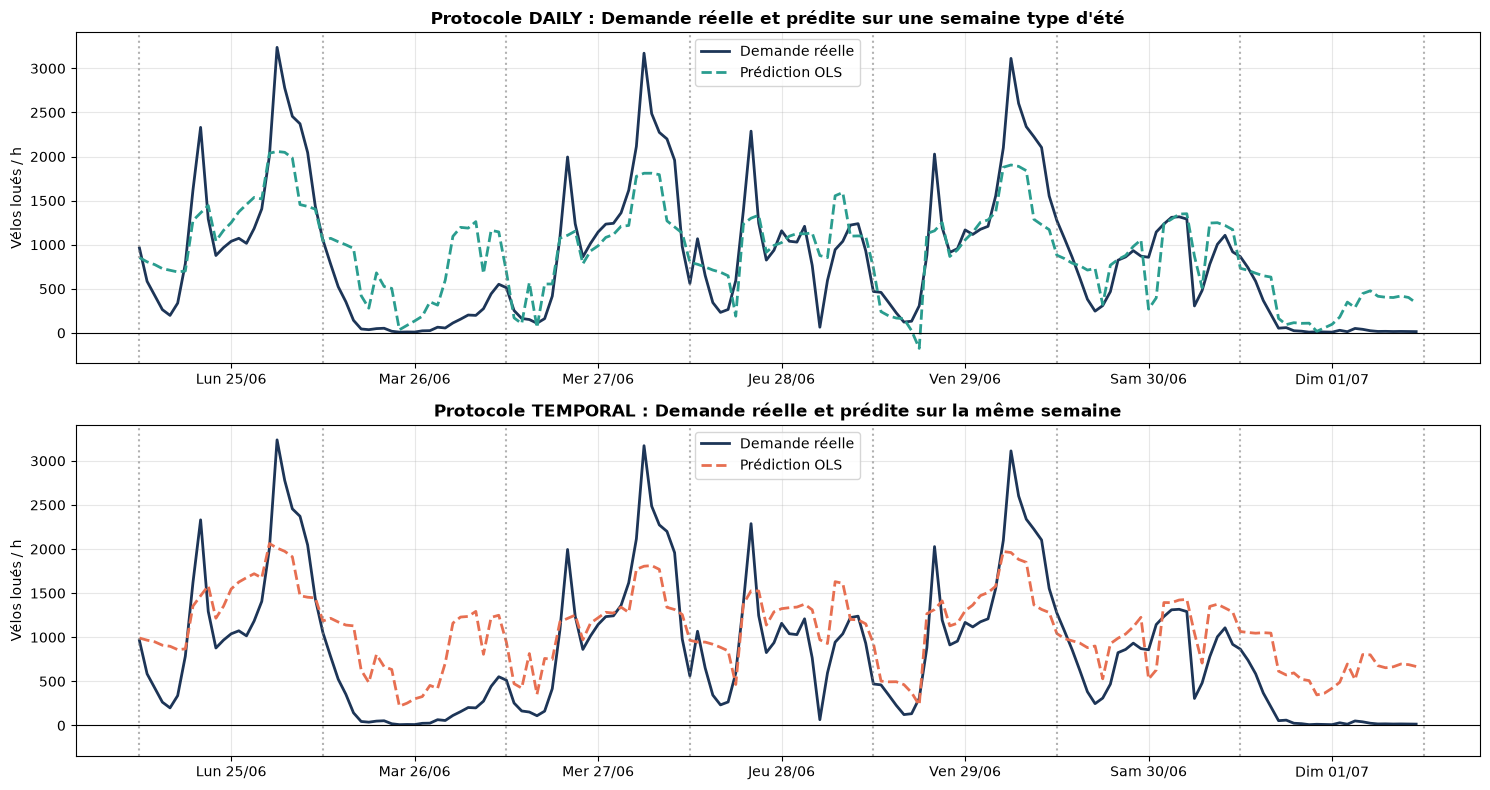

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharey=True)

# Daily
semaine_d = analyse_daily[(analyse_daily["date"] >= "2018-06-25") & (analyse_daily["date"] <= "2018-07-01")].sort_values(["date", "hour"])
temps_d = range(len(semaine_d))
axes[0].plot(temps_d, semaine_d[TARGET].values, label="Demande réelle", color="#1d3557", linewidth=2)
axes[0].plot(temps_d, semaine_d["prediction"].values, "--", label="Prédiction OLS", color="#2a9d8f", linewidth=2)
jours_semaine = ["Lun 25/06", "Mar 26/06", "Mer 27/06", "Jeu 28/06", "Ven 29/06", "Sam 30/06", "Dim 01/07"]
axes[0].set_xticks(range(12, len(semaine_d), 24))
axes[0].set_xticklabels(jours_semaine)
for x in range(0, len(semaine_d) + 1, 24):
    axes[0].axvline(x, color="grey", linestyle=":", alpha=0.6)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Vélos loués / h")
axes[0].set_title("Protocole DAILY : Demande réelle et prédite sur une semaine type d'été", fontweight="bold")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Temporal
semaine_t = analyse_temporal[(analyse_temporal["date"] >= "2018-06-25") & (analyse_temporal["date"] <= "2018-07-01")].sort_values(["date", "hour"])
temps_t = range(len(semaine_t))
axes[1].plot(temps_t, semaine_t[TARGET].values, label="Demande réelle", color="#1d3557", linewidth=2)
axes[1].plot(temps_t, semaine_t["prediction"].values, "--", label="Prédiction OLS", color="#e76f51", linewidth=2)
axes[1].set_xticks(range(12, len(semaine_t), 24))
axes[1].set_xticklabels(jours_semaine)
for x in range(0, len(semaine_t) + 1, 24):
    axes[1].axvline(x, color="grey", linestyle=":", alpha=0.6)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Vélos loués / h")
axes[1].set_title("Protocole TEMPORAL : Demande réelle et prédite sur la même semaine", fontweight="bold")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

- **Les pics sont fortement sous-estimés** : le soir, la demande dépasse 3 000 vélos/h le lundi, le mercredi et le vendredi, mais le modèle prédit ≈ 1 800 à 2 000. Le matin, les pics de ≈ 2 000 à 2 300 sont prédits vers 1 300.
- **Le mardi 26/06**, la demande reste très basse toute la journée (jour de forte pluie), alors que le modèle prédit plus de 1 000 vélos/h l'après-midi : il ne réagit qu'à la pluie de l'heure en cours.
- **Le vendredi tôt le matin**, la prédiction passe **sous 0**.
- Le **samedi**, les ordres de grandeur sont justes. Le **dimanche 01/07** (49 mm de pluie), la demande reste presque nulle à partir de 6 h (moins de 30 vélos/h en moyenne), mais le modèle prédit 300 à 400 vélos/h l'après-midi et le soir : comme le mardi, il réagit mal à une journée entière de pluie.

#### Prédit en fonction du réel

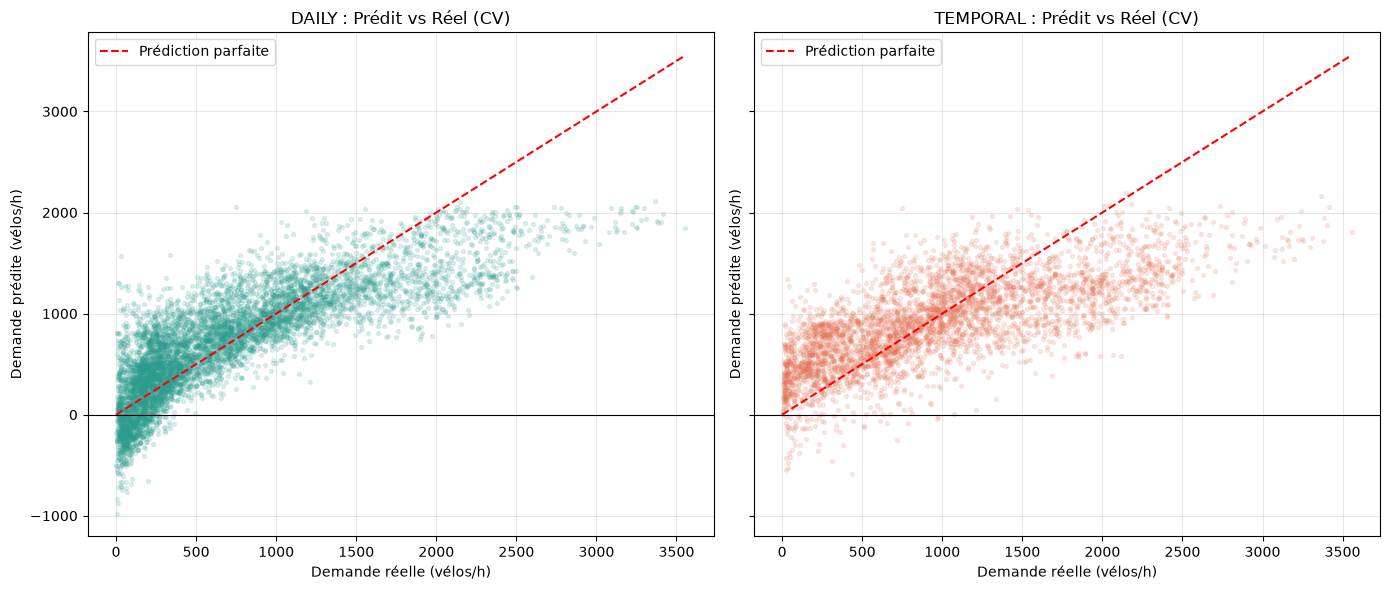

DAILY    - Prédictions négatives : 10.2% (min : -979)
TEMPORAL - Prédictions négatives : 1.6% (min : -585)


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, df_a, nom, col in zip(axes, [analyse_daily, analyse_temporal], ["DAILY", "TEMPORAL"], ["#2a9d8f", "#e76f51"]):
    ax.scatter(df_a[TARGET], df_a["prediction"], alpha=0.15, s=8, color=col)
    limite = df_a[TARGET].max()
    ax.plot([0, limite], [0, limite], "r--", label="Prédiction parfaite")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(xlabel="Demande réelle (vélos/h)", ylabel="Demande prédite (vélos/h)", title=f"{nom} : Prédit vs Réel (CV)")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

print(f"DAILY    - Prédictions négatives : {(analyse_daily['prediction'] < 0).mean():.1%} (min : {analyse_daily['prediction'].min():.0f})")
print(f"TEMPORAL - Prédictions négatives : {(analyse_temporal['prediction'] < 0).mean():.1%} (min : {analyse_temporal['prediction'].min():.0f})")


Si le modèle était parfait, tous les points seraient sur la diagonale rouge. On voit deux défauts :
- **les fortes demandes sont sous-estimées** : pour les heures à plus de 2 000 vélos, le modèle prédit en moyenne ≈ 1 600 au lieu de ≈ 2 360 (les points sont sous la diagonale à droite) ;
- **le modèle prédit parfois une demande négative** (≈ 10 % des heures, jusqu'à ≈ −980), ce qui est impossible. Une somme pondérée n'a aucune raison de rester positive : la nuit, en hiver, sous la pluie, les effets négatifs s'additionnent et font passer la prédiction sous 0.

**Conclusion du modèle 1** : il capte les grandes tendances (saison, météo), mais il est trop simple pour reproduire la forme de la journée. La prochaine étape est de lui donner des variables qui décrivent mieux l'heure.

## 5. Modèle 2 : régularisation (Ridge et Lasso)

La **régularisation** ajoute à l'erreur une **pénalité sur la taille des poids**, pour empêcher le modèle de prendre des poids trop grands :

| Modèle | Ce qui est minimisé | Effet sur les poids |
|---|---|---|
| OLS (`LinearRegression`) | $\sum (\hat{y} - y)^2$ | aucun frein |
| Ridge | $\sum (\hat{y} - y)^2 + \alpha \sum w_j^2$ | poids rétrécis, jamais nuls |
| Lasso | $\sum (\hat{y} - y)^2 + \alpha \sum \lvert w_j \rvert$ | certains poids mis **exactement à 0** : les variables inutiles sont éliminées |

$\alpha$ (souvent noté $\lambda$) règle la force du frein. On ne peut pas le choisir à l'entraînement : on essaie plusieurs valeurs et on garde celle qui donne la plus petite **RMSE CV**. La normalisation est ici indispensable, sinon la pénalité toucherait différemment les variables selon leur échelle.

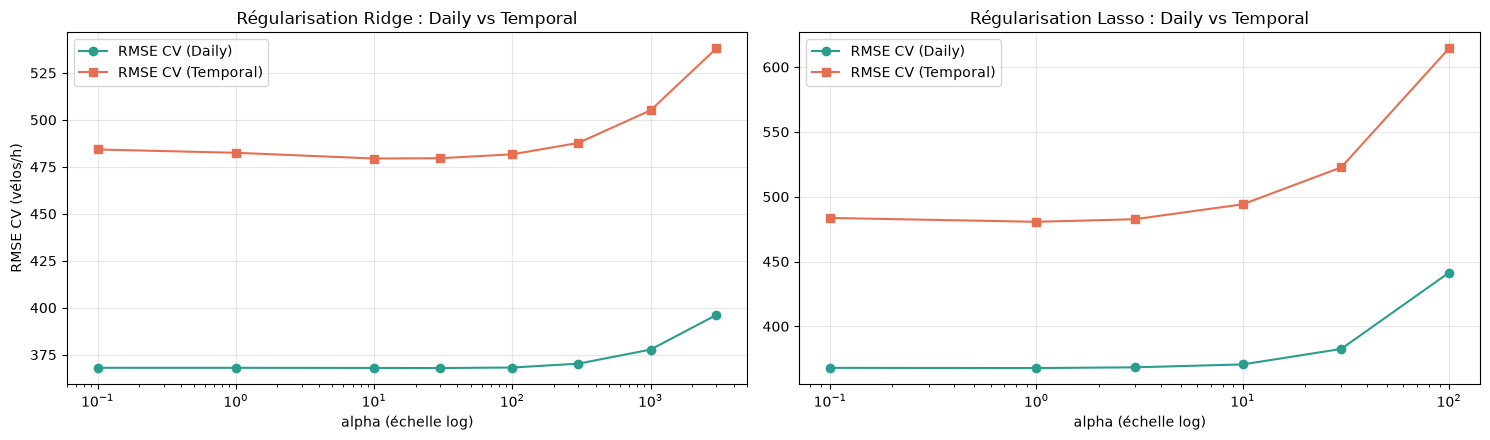

,modèle,alpha,Daily RMSE train,Daily RMSE CV,Temporal RMSE train,Temporal RMSE CV
0,Ridge,0.1,361.8,368.0,288.1,484.3
1,Ridge,1.0,361.8,368.0,288.1,482.5
2,Ridge,10.0,361.8,367.9,288.5,479.5
3,Ridge,30.0,361.9,367.9,289.2,479.6
4,Ridge,100.0,362.5,368.2,290.4,481.7
5,Ridge,300.0,365.1,370.2,292.5,487.7
6,Ridge,1000.0,373.4,377.7,299.4,505.1
7,Ridge,3000.0,392.8,396.2,316.7,538.1
8,Lasso,0.1,361.8,368.0,288.1,483.6
9,Lasso,1.0,362.0,367.8,288.9,480.6


In [11]:
from sklearn.linear_model import Ridge, Lasso

alphas_ridge = [0.1, 1, 10, 30, 100, 300, 1000, 3000]
alphas_lasso = [0.1, 1, 3, 10, 30, 100]

courbes = []
for nom, Modele, alphas in [("Ridge", Ridge, alphas_ridge), ("Lasso", Lasso, alphas_lasso)]:
    for alpha in alphas:
        regresseur = Modele(alpha=alpha, max_iter=50000) if nom == "Lasso" else Modele(alpha=alpha)
        # CV Daily
        s_d = cross_validate(make_pipeline(StandardScaler(), regresseur), X_train, y_train, cv=splits,
                             scoring="neg_root_mean_squared_error", return_train_score=True, n_jobs=-1)
        # CV Temporal
        s_t = cross_validate(make_pipeline(StandardScaler(), regresseur), X_train_temporal, y_train_temporal, cv=splits_temporal,
                             scoring="neg_root_mean_squared_error", return_train_score=True, n_jobs=-1)
        courbes.append({
            "modèle": nom, "alpha": alpha,
            "Daily RMSE train": -s_d["train_score"].mean(), "Daily RMSE CV": -s_d["test_score"].mean(),
            "Temporal RMSE train": -s_t["train_score"].mean(), "Temporal RMSE CV": -s_t["test_score"].mean()
        })
courbes = pd.DataFrame(courbes)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, nom in zip(axes, ["Ridge", "Lasso"]):
    c = courbes[courbes["modèle"] == nom]
    ax.plot(c["alpha"], c["Daily RMSE CV"], "o-", color="#2a9d8f", label="RMSE CV (Daily)")
    ax.plot(c["alpha"], c["Temporal RMSE CV"], "s-", color="#e76f51", label="RMSE CV (Temporal)")
    ax.set(xscale="log", xlabel="alpha (échelle log)", title=f"Régularisation {nom} : Daily vs Temporal")
    ax.legend()
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("RMSE CV (vélos/h)")
plt.tight_layout()
plt.show()

display(courbes.round(1))


On ajoute au tableau de suivi le meilleur Ridge et le meilleur Lasso (la plus petite RMSE CV) :

In [12]:
meilleur_ridge = courbes[courbes["modèle"] == "Ridge"].sort_values("Daily RMSE CV").iloc[0]["alpha"]
meilleur_lasso = courbes[courbes["modèle"] == "Lasso"].sort_values("Daily RMSE CV").iloc[0]["alpha"]

evaluer(f"2a. Ridge (alpha={meilleur_ridge:g})",
        make_pipeline(StandardScaler(), Ridge(alpha=meilleur_ridge)), X_train)
evaluer(f"2b. Lasso (alpha={meilleur_lasso:g})",
        make_pipeline(StandardScaler(), Lasso(alpha=meilleur_lasso, max_iter=50000)), X_train)


,RMSE CV (Daily),R² CV (Daily),RMSE CV (Temporal),R² CV (Temporal)
Modèle,,,,
0. Moyenne (référence),644.8,-0.002,809.7,-0.528
1. Régression linéaire (25 variables),368.0,0.673,484.5,0.436
2a. Ridge (alpha=30),367.9,0.674,479.6,0.449
2b. Lasso (alpha=1),367.8,0.674,480.6,0.449


**Daily** : la régularisation ne change presque rien. Le meilleur Ridge (α = 30) et le meilleur Lasso (α = 1) ont la même RMSE CV que la régression simple (**368 vélos/h**). C'est logique : la régularisation réduit la **variance** (le sur-apprentissage), alors que le modèle 1 a un problème de **biais**. Freiner les poids d'un modèle déjà trop rigide ne l'aide pas.

**Temporal** : petit gain. La RMSE CV passe de 484,5 à **479,6 vélos/h** et le R² de 0,436 à **0,449**. En limitant la taille des poids, la pénalité rend le modèle un peu plus stable quand la saison change.

### Ce que le Lasso révèle : les variables inutiles

En augmentant $\alpha$, le Lasso met de plus en plus de poids à 0. On regarde quelles variables il élimine en premier :

In [13]:
for alpha in [1, 10]:
    lasso_d = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=50000)).fit(X_train, y_train)
    coef_d = pd.Series(lasso_d[-1].coef_, index=FEATURES)
    zero_d = coef_d[coef_d == 0].index.tolist()
    
    lasso_t = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=50000)).fit(X_train_temporal, y_train_temporal)
    coef_t = pd.Series(lasso_t[-1].coef_, index=FEATURES)
    zero_t = coef_t[coef_t == 0].index.tolist()
    
    print(f"Lasso alpha={alpha:2d} | Variables annulées (DAILY)    : {len(zero_d)} -> {zero_d}")
    print(f"Lasso alpha={alpha:2d} | Variables annulées (TEMPORAL) : {len(zero_t)} -> {zero_t}\n")


Lasso alpha= 1 | Variables annulées (DAILY)    : 4 -> ['solar_radiation', 'month', 'season_Summer', 'season_Winter']
Lasso alpha= 1 | Variables annulées (TEMPORAL) : 2 -> ['solar_radiation', 'season_Winter']

Lasso alpha=10 | Variables annulées (DAILY)    : 11 -> ['wind_speed', 'visibility', 'solar_radiation', 'snowfall', 'year', 'day', 'cos_hour', 'sin_month', 'season_Spring', 'season_Summer', 'season_Winter']
Lasso alpha=10 | Variables annulées (TEMPORAL) : 10 -> ['wind_speed', 'visibility', 'solar_radiation', 'snowfall', 'month', 'day', 'sin_month', 'season_Spring', 'season_Summer', 'season_Winter']



Même s'il n'améliore pas l'erreur, le Lasso apporte une information utile :
- **α = 1** : il élimine `solar_radiation`, `month`, `season_Summer` et `season_Winter` **sans perte** de performance. Ça confirme que les variables de calendrier sont **redondantes** (le mois, les saisons, `sin_month` et `cos_month` décrivent la même chose), comme on l'avait vu avec les coefficients ;
- **α = 10** : il élimine **11 variables sur 25** (vent, visibilité, ensoleillement, neige en cm, `year`, `day`…) pour seulement +2,8 vélos/h d'erreur. Un modèle presque deux fois plus simple, presque aussi bon.

**Conclusion** : avec ces 25 variables, on ne peut pas faire beaucoup mieux qu'une RMSE CV d'environ 368. Le problème n'est pas le réglage du modèle mais **l'information qu'on lui donne**. En cas de biais élevé, la bonne démarche est d'**ajouter des variables** : c'est l'étape suivante (feature engineering).

## 6. Modèle 3 : feature engineering

Les sections 4 et 5 ont montré que le modèle a un **biais élevé** : il manque d'information pour décrire la demande, et la régularisation n'y change rien. Le *feature engineering* consiste à **créer de nouvelles variables** à partir de celles qu'on a.

**Méthode** : on regarde **où le modèle 1 se trompe de façon systématique**. Une erreur qui se répète toujours dans les mêmes conditions (même heure, même température) signifie qu'il manque une information au modèle, et indique quelle variable ajouter.

L'erreur est calculée comme **prédiction − réel**, avec les prédictions hors pli de la section 4 : une erreur positive veut dire que le modèle **surestime**, une erreur négative qu'il **sous-estime**.

### 6.1 Les erreurs du modèle 1 selon l'heure

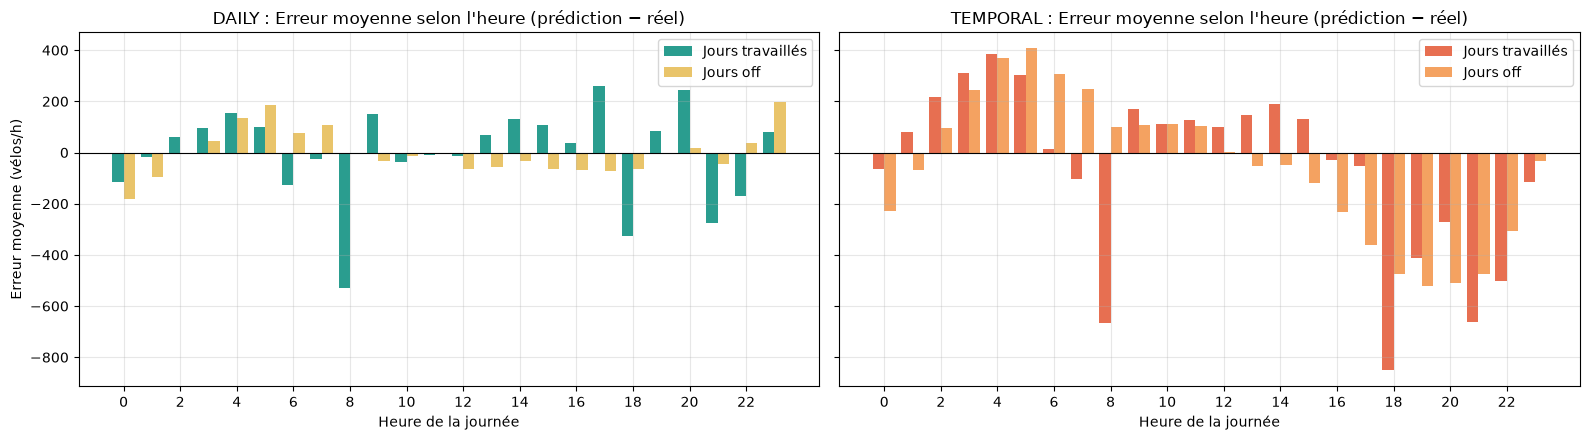

In [14]:
analyse_daily["erreur"] = analyse_daily["prediction"] - analyse_daily[TARGET]
analyse_daily["jour_off"] = ((analyse_daily["is_weekend"] == 1) | (analyse_daily["holiday"] == 1)).astype(int)

analyse_temporal["erreur"] = analyse_temporal["prediction"] - analyse_temporal[TARGET]
analyse_temporal["jour_off"] = ((analyse_temporal["is_weekend"] == 1) | (analyse_temporal["holiday"] == 1)).astype(int)

err_h_d = analyse_daily.groupby(["hour", "jour_off"])["erreur"].mean().unstack()
err_h_t = analyse_temporal.groupby(["hour", "jour_off"])["erreur"].mean().unstack()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
largeur = 0.4

# DAILY
axes[0].bar(err_h_d.index - largeur / 2, err_h_d[0], width=largeur, label="Jours travaillés", color="#2a9d8f")
axes[0].bar(err_h_d.index + largeur / 2, err_h_d[1], width=largeur, label="Jours off", color="#e9c46a")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(xlabel="Heure de la journée", ylabel="Erreur moyenne (vélos/h)", xticks=range(0, 24, 2),
            title="DAILY : Erreur moyenne selon l'heure (prédiction − réel)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# TEMPORAL
axes[1].bar(err_h_t.index - largeur / 2, err_h_t[0], width=largeur, label="Jours travaillés", color="#e76f51")
axes[1].bar(err_h_t.index + largeur / 2, err_h_t[1], width=largeur, label="Jours off", color="#f4a261")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Heure de la journée", xticks=range(0, 24, 2),
            title="TEMPORAL : Erreur moyenne selon l'heure (prédiction − réel)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Les erreurs sont **énormes et systématiques** les jours travaillés :
- à **8 h**, le modèle sous-estime de ≈ **530 vélos/h**, et à 18 h de ≈ 330 ;
- juste à côté, il surestime : ≈ +150 à 9 h, ≈ +260 à 17 h ;
- la nuit, il surestime (≈ +155 à 4 h).

Ces erreurs viennent de `is_rush_hour`, qui ajoute le même nombre de vélos de 7 h à 9 h et de 17 h à 20 h en semaine : le modèle fait des paliers au lieu de pics.

Les jours off, les erreurs sont **beaucoup plus petites et ne suivent pas le même motif** : le profil horaire n'est pas le même.

**Variables ajoutées :**
- **une colonne 0/1 par heure** (`heure_0` … `heure_23`) : le modèle pourra apprendre un effet propre à chaque heure ;
- **une colonne par heure pour les jours off** (`heure_0_off` … `heure_23_off`) : il pourra apprendre un profil différent pour les week-ends et les jours fériés.

### 6.2 Les erreurs du modèle 1 selon la température

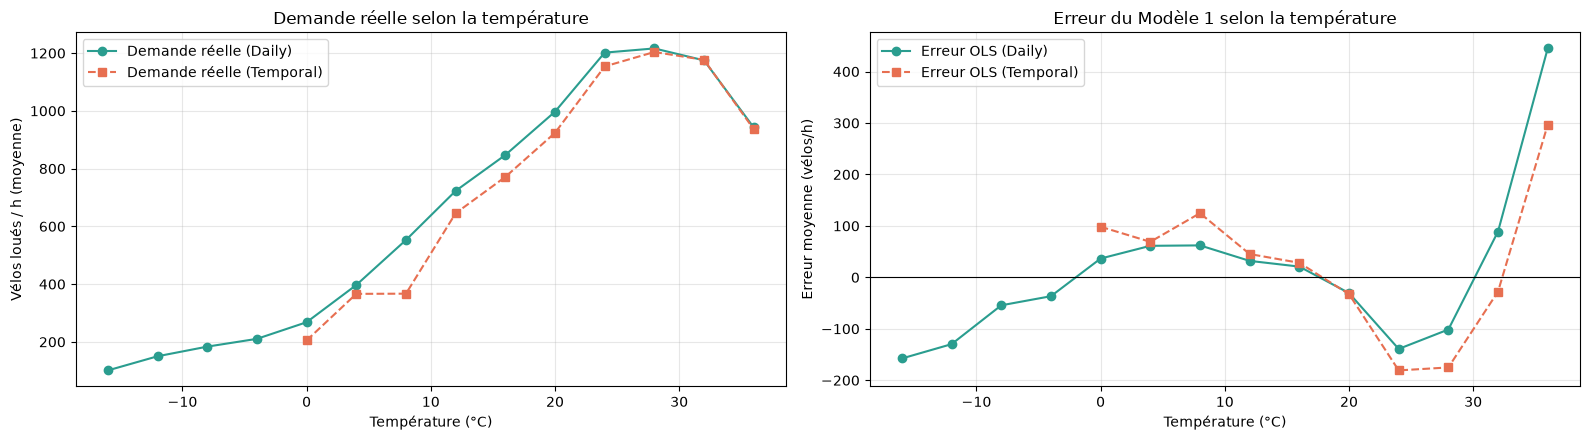

In [15]:
tranches_d = pd.cut(analyse_daily["temperature"], bins=range(-18, 42, 4))
par_tranche_d = analyse_daily.groupby(tranches_d, observed=True).agg(demande=(TARGET, "mean"), erreur=("erreur", "mean"))
milieux_d = [t.mid for t in par_tranche_d.index]

tranches_t = pd.cut(analyse_temporal["temperature"], bins=range(-18, 42, 4))
par_tranche_t = analyse_temporal.groupby(tranches_t, observed=True).agg(demande=(TARGET, "mean"), erreur=("erreur", "mean"))
milieux_t = [t.mid for t in par_tranche_t.index]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

# Demande réelle
axes[0].plot(milieux_d, par_tranche_d["demande"], "o-", color="#2a9d8f", label="Demande réelle (Daily)")
axes[0].plot(milieux_t, par_tranche_t["demande"], "s--", color="#e76f51", label="Demande réelle (Temporal)")
axes[0].set(xlabel="Température (°C)", ylabel="Vélos loués / h (moyenne)",
            title="Demande réelle selon la température")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Erreur
axes[1].plot(milieux_d, par_tranche_d["erreur"], "o-", color="#2a9d8f", label="Erreur OLS (Daily)")
axes[1].plot(milieux_t, par_tranche_t["erreur"], "s--", color="#e76f51", label="Erreur OLS (Temporal)")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Température (°C)", ylabel="Erreur moyenne (vélos/h)",
            title="Erreur du Modèle 1 selon la température")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

- La demande monte avec la température jusqu'à ≈ 26 °C, puis **redescend**. Une droite ne peut pas faire demi-tour : le modèle **surestime** fortement les journées très chaudes (≈ **+445 vélos/h** entre 34 et 38 °C).
- L'erreur change de signe plusieurs fois : le modèle sous-estime par grand froid (≈ −160), surestime entre 2 et 10 °C (≈ +60), sous-estime entre 22 et 26 °C (≈ −140), puis surestime au-delà de 30 °C.

**Variable ajoutée : des tranches de température**, une colonne 0/1 par tranche de 4 °C. Le modèle apprend un effet propre à chaque tranche et peut suivre cette forme irrégulière, ce qu'une seule variable `temperature` ne permet pas.

### 6.3 Le modèle 3

Le modèle 3 est la régression linéaire sur les 25 variables de départ + les colonnes par heure + les colonnes par heure des jours off + les tranches de température.

In [16]:
def ajouter_heures(X):
    return pd.concat([X, pd.get_dummies(X["hour"], prefix="heure", dtype=int)], axis=1)


def ajouter_heures_jour_off(X):
    jour_off = ((X["is_weekend"] == 1) | (X["holiday"] == 1)).astype(int)
    colonnes_off = pd.get_dummies(X["hour"], prefix="heure", dtype=int).mul(jour_off, axis=0).add_suffix("_off")
    return pd.concat([X, colonnes_off], axis=1)


def ajouter_tranches_temperature(X):
    tranches = pd.cut(X["temperature"], bins=range(-20, 45, 4))
    return pd.concat([X, pd.get_dummies(tranches, prefix="temp", dtype=int)], axis=1)


def feature_engineering(X):
    return ajouter_tranches_temperature(ajouter_heures_jour_off(ajouter_heures(X)))


X_train_3 = feature_engineering(X_train)
X_train_temporal_3 = feature_engineering(X_train_temporal)
print(f"Variables initiales : {X_train.shape[1]} -> Après Feature Engineering : {X_train_3.shape[1]}")

evaluer("3. Feature engineering (89 variables)",
        make_pipeline(StandardScaler(), LinearRegression()),
        X_train_3)


Variables initiales : 25 -> Après Feature Engineering : 89


,RMSE CV (Daily),R² CV (Daily),RMSE CV (Temporal),R² CV (Temporal)
Modèle,,,,
0. Moyenne (référence),644.8,-0.002,809.7,-0.528
1. Régression linéaire (25 variables),368.0,0.673,484.5,0.436
2a. Ridge (alpha=30),367.9,0.674,479.6,0.449
2b. Lasso (alpha=1),367.8,0.674,480.6,0.449
3. Feature engineering (89 variables),315.1,0.760,426.0,0.569


**Daily** : la RMSE CV passe de 368 à **315 vélos/h** et le R² de 0,67 à **0,76**. L'erreur train (305) et l'erreur CV (315) baissent ensemble : le biais diminue sans sur-apprentissage.

**Temporal** : la RMSE CV passe de 480 à **426 vélos/h** et le R² de 0,45 à **0,57**. Avec les colonnes par heure et les tranches de température, le modèle suit mieux les pics de la journée et la baisse de la demande quand il fait très chaud.

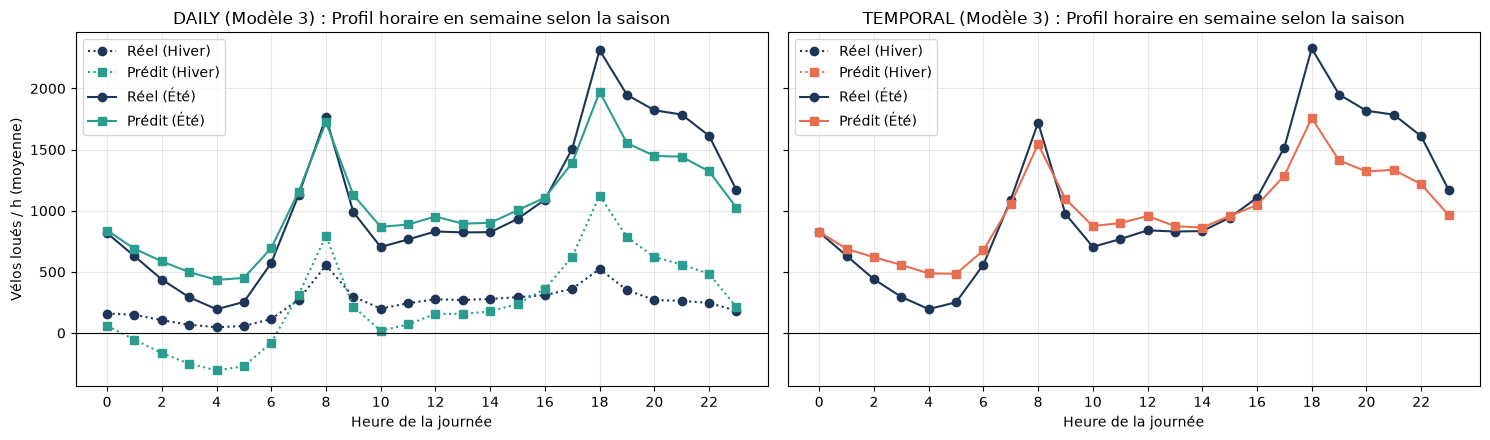

DAILY    - Prédictions négatives (Modèle 3) : 10.8% des heures
TEMPORAL - Prédictions négatives (Modèle 3) : 1.3% des heures


In [17]:
pred_3_daily = cross_val_predict(make_pipeline(StandardScaler(), LinearRegression()), X_train_3, y_train, cv=splits)
analyse_3_daily = train.assign(prediction=pred_3_daily)

analyse_3_temporal = predire_cv_temporal(
    make_pipeline(StandardScaler(), LinearRegression()),
    X_train_temporal_3, y_train_temporal, splits_temporal, train_temporal
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)

# DAILY
for saison, style in [("season_Winter", ":"), ("season_Summer", "-")]:
    nom_saison = "Hiver" if saison == "season_Winter" else "Été"
    subset = analyse_3_daily[(analyse_3_daily[saison] == 1) & (analyse_3_daily["is_weekend"] == 0)]
    ph = subset.groupby("hour")[[TARGET, "prediction"]].mean()
    axes[0].plot(ph.index, ph[TARGET], "o" + style, color="#1d3557", label=f"Réel ({nom_saison})")
    axes[0].plot(ph.index, ph["prediction"], "s" + style, color="#2a9d8f", label=f"Prédit ({nom_saison})")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(xlabel="Heure de la journée", ylabel="Vélos loués / h (moyenne)", xticks=range(0, 24, 2),
            title="DAILY (Modèle 3) : Profil horaire en semaine selon la saison")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# TEMPORAL
for saison, style in [("season_Winter", ":"), ("season_Summer", "-")]:
    nom_saison = "Hiver" if saison == "season_Winter" else "Été"
    subset = analyse_3_temporal[(analyse_3_temporal[saison] == 1) & (analyse_3_temporal["is_weekend"] == 0)]
    ph = subset.groupby("hour")[[TARGET, "prediction"]].mean()
    axes[1].plot(ph.index, ph[TARGET], "o" + style, color="#1d3557", label=f"Réel ({nom_saison})")
    axes[1].plot(ph.index, ph["prediction"], "s" + style, color="#e76f51", label=f"Prédit ({nom_saison})")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Heure de la journée", xticks=range(0, 24, 2),
            title="TEMPORAL (Modèle 3) : Profil horaire en semaine selon la saison")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"DAILY    - Prédictions négatives (Modèle 3) : {(pred_3_daily < 0).mean():.1%} des heures")
print(f"TEMPORAL - Prédictions négatives (Modèle 3) : {(analyse_3_temporal['prediction'] < 0).mean():.1%} des heures")


Le modèle 3 ajoute **le même pic** quelle que soit la saison, puis décale toute la courbe vers le haut ou vers le bas selon la météo :
- **en hiver**, il **surestime** fortement les pics (≈ 1 120 vélos/h prédits à 18 h contre ≈ 520 en réalité) et prédit des valeurs **négatives la nuit** (≈ −300 à 4 h) ;
- **en été**, il **sous-estime** les pics (≈ 1 980 prédits à 18 h contre ≈ 2 310).

En réalité, le pic de 18 h est **quatre fois plus haut en été qu'en hiver** : l'effet de l'heure **dépend** de la saison et de la météo. Une régression linéaire **additionne** les effets et ne peut pas représenter ça, même avec de nouvelles variables.

**Étape suivante** : ajouter des **combinaisons de variables** (par exemple heure × température) avec la régression polynomiale, et contrôler le risque de sur-apprentissage avec la régularisation.

## 7. Modèle 4 : choix du degré de la régression polynomiale

La **régression polynomiale** ajoute des **combinaisons de variables** : avec `PolynomialFeatures(degree=2)`, on ajoute tous les carrés ($x_1^2$, $x_2^2$…) et tous les produits de deux variables ($x_1 \times x_2$…), par exemple `temperature × hour` ou `is_raining × is_rush_hour`. Le modèle reste une régression linéaire, mais sur ces nouvelles variables, et l'effet d'une variable peut maintenant **dépendre des autres** : c'est ce qui manquait au modèle 3.

On essaie plusieurs **degrés** et on garde celui qui donne la plus petite RMSE CV. On part des **25 variables de base**, car le nombre de variables créées explose avec le degré :

| Degré | Variables créées (à partir de 25) |
|---|---|
| 1 | 25 |
| 2 | 350 |
| 3 | 3 275 |
| 4 | 23 750 |

On s'arrête au degré 3 : au degré 4, il y aurait plus de variables (23 750) que d'heures d'entraînement (≈ 5 400).

Dans le pipeline, `VarianceThreshold` retire les combinaisons **constantes** sur les données d'entraînement (par exemple `holiday × season_Winter` quand aucun jour férié d'hiver n'est dans le pli). Sans ça, la normalisation diviserait par un écart-type quasi nul.

In [18]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.feature_selection import VarianceThreshold

degres = [1, 2, 3]
poly_comparaison = []

for degre in degres:
    modele = make_pipeline(
        PolynomialFeatures(degre, include_bias=False),
        VarianceThreshold(1e-6),
        StandardScaler(),
        LinearRegression(),
    )
    # CV DAILY
    s_d = cross_validate(modele, X_train, y_train, cv=splits,
                         scoring="neg_root_mean_squared_error", return_train_score=True, n_jobs=-1)
    # CV TEMPORAL
    s_t = cross_validate(modele, X_train_temporal, y_train_temporal, cv=splits_temporal,
                         scoring="neg_root_mean_squared_error", return_train_score=True, n_jobs=-1)
    poly_comparaison.append({
        "degré": degre,
        "Daily RMSE train": -s_d["train_score"].mean(), "Daily RMSE CV": -s_d["test_score"].mean(),
        "Temporal RMSE train": -s_t["train_score"].mean(), "Temporal RMSE CV": -s_t["test_score"].mean()
    })
    print(f"Degré {degre} : Daily CV = {-s_d['test_score'].mean():.1f} | Temporal CV = {-s_t['test_score'].mean():.1f}")

poly_comparaison = pd.DataFrame(poly_comparaison)
train_rmses = poly_comparaison["Daily RMSE train"].tolist()
cv_rmses = poly_comparaison["Daily RMSE CV"].tolist()


Degré 1 : Daily CV = 368.0 | Temporal CV = 484.5


Degré 2 : Daily CV = 286.8 | Temporal CV = 28727.3


Degré 3 : Daily CV = 18042.4 | Temporal CV = 9501.6


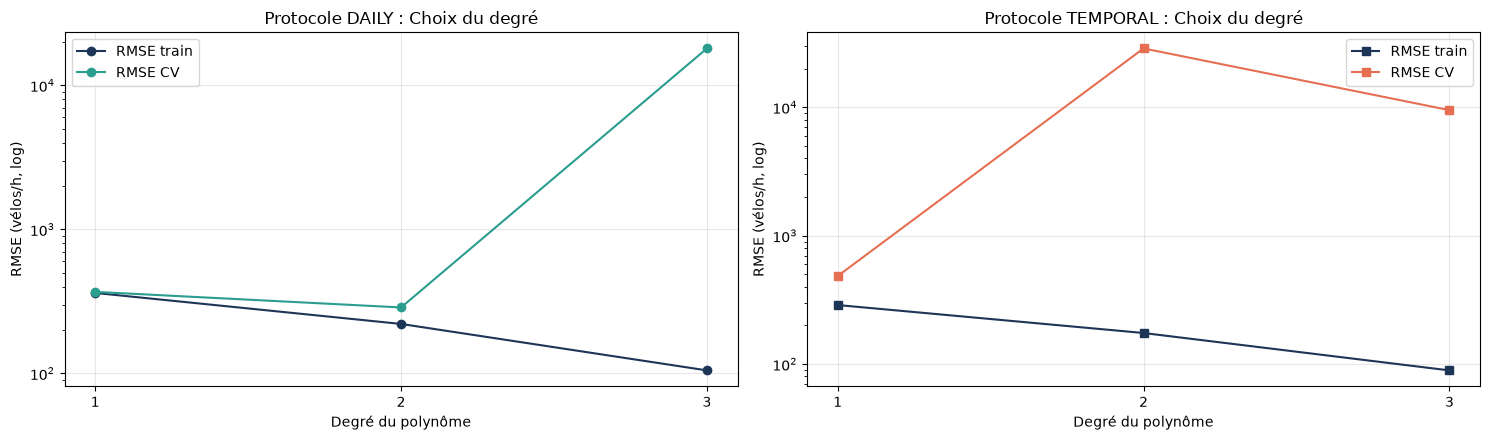

,degré,Daily RMSE train,Daily RMSE CV,Temporal RMSE train,Temporal RMSE CV
0,1,361.8,368.0,288.1,484.5
1,2,220.4,286.8,174.5,28727.3
2,3,104.8,18042.4,89.2,9501.6


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# DAILY
axes[0].plot(poly_comparaison["degré"], poly_comparaison["Daily RMSE train"], "o-", color="#1d3557", label="RMSE train")
axes[0].plot(poly_comparaison["degré"], poly_comparaison["Daily RMSE CV"], "o-", color="#2a9d8f", label="RMSE CV")
axes[0].set_yscale("log")
axes[0].set_xticks(degres)
axes[0].set(xlabel="Degré du polynôme", ylabel="RMSE (vélos/h, log)", title="Protocole DAILY : Choix du degré")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# TEMPORAL
axes[1].plot(poly_comparaison["degré"], poly_comparaison["Temporal RMSE train"], "s-", color="#1d3557", label="RMSE train")
axes[1].plot(poly_comparaison["degré"], poly_comparaison["Temporal RMSE CV"], "s-", color="#e76f51", label="RMSE CV")
axes[1].set_yscale("log")
axes[1].set_xticks(degres)
axes[1].set(xlabel="Degré du polynôme", ylabel="RMSE (vélos/h, log)", title="Protocole TEMPORAL : Choix du degré")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

display(poly_comparaison.round(1))


On retrouve le compromis entre biais et variance :

**Daily**
- **degré 1** : RMSE train ≈ RMSE CV (362 et 368) → biais élevé ;
- **degré 2** : les deux erreurs baissent (220 et **287**) → meilleur degré ;
- **degré 3** : la RMSE train baisse encore (105) mais la RMSE CV explose (≈ 18 000) → sur-apprentissage.

**Temporal**
- dès le **degré 2**, la RMSE CV explose (**28 727 vélos/h**). Avec 350 variables, dont beaucoup sont très corrélées, et sans pénalité, les poids deviennent énormes et les prédictions sur les semaines suivantes n'ont plus de sens. Il faut régulariser.

In [20]:
meilleur_degre = int(poly_comparaison.loc[poly_comparaison["Daily RMSE CV"].idxmin()]["degré"])

evaluer(f"4. Régression polynomiale (degré {meilleur_degre})",
        make_pipeline(PolynomialFeatures(meilleur_degre, include_bias=False), VarianceThreshold(1e-6),
                      StandardScaler(), LinearRegression()),
        X_train)


,RMSE CV (Daily),R² CV (Daily),RMSE CV (Temporal),R² CV (Temporal)
Modèle,,,,
0. Moyenne (référence),644.8,-0.002,809.7,-0.528
1. Régression linéaire (25 variables),368.0,0.673,484.5,0.436
2a. Ridge (alpha=30),367.9,0.674,479.6,0.449
2b. Lasso (alpha=1),367.8,0.674,480.6,0.449
3. Feature engineering (89 variables),315.1,0.760,426.0,0.569
4. Régression polynomiale (degré 2),286.8,0.799,28727.3,-33861.353


- La régression polynomiale de degré 2 fait **mieux que le feature engineering** : RMSE CV de **287** contre 315, R² de **0,80**. Les combinaisons de variables (par exemple `temperature × hour` ou `season_Winter × is_rush_hour`) permettent enfin à l'effet de l'heure de **dépendre** de la saison et de la météo.
- Mais un nouveau problème apparaît : la RMSE CV (287) est nettement **plus haute que la RMSE train** (220). Le modèle commence à **apprendre par cœur** : c'est le début de la **variance**, qui explose au degré 3.

**Étape suivante** : c'est maintenant que la **régularisation** devient utile. Elle doit permettre de garder les combinaisons de variables (pour réduire le biais) tout en freinant le sur-apprentissage (pour réduire la variance).

## 8. Modèle 5 : régression polynomiale avec régularisation Ridge

La régression polynomiale réduit le biais, mais elle crée de la **variance** : au degré 2, la RMSE CV (287) est déjà nettement au-dessus de la RMSE train (220), et au degré 3 elle explose. La **régularisation Ridge** freine les poids pour limiter ce sur-apprentissage, tout en gardant les combinaisons de variables.

On choisit **ensemble** le degré, les variables de départ et la force du frein α, par cross-validation. On compare trois configurations :
- **degré 2** sur les 25 variables de base (350 variables) ;
- **degré 3** sur les 25 variables de base (3 275 variables), inutilisable sans régularisation ;
- **degré 2 sur les variables du feature engineering** de la section 6 (89 variables de départ, ≈ 4 000 combinaisons).

Pour chacune, on essaie plusieurs valeurs de α (le calcul prend environ une minute).

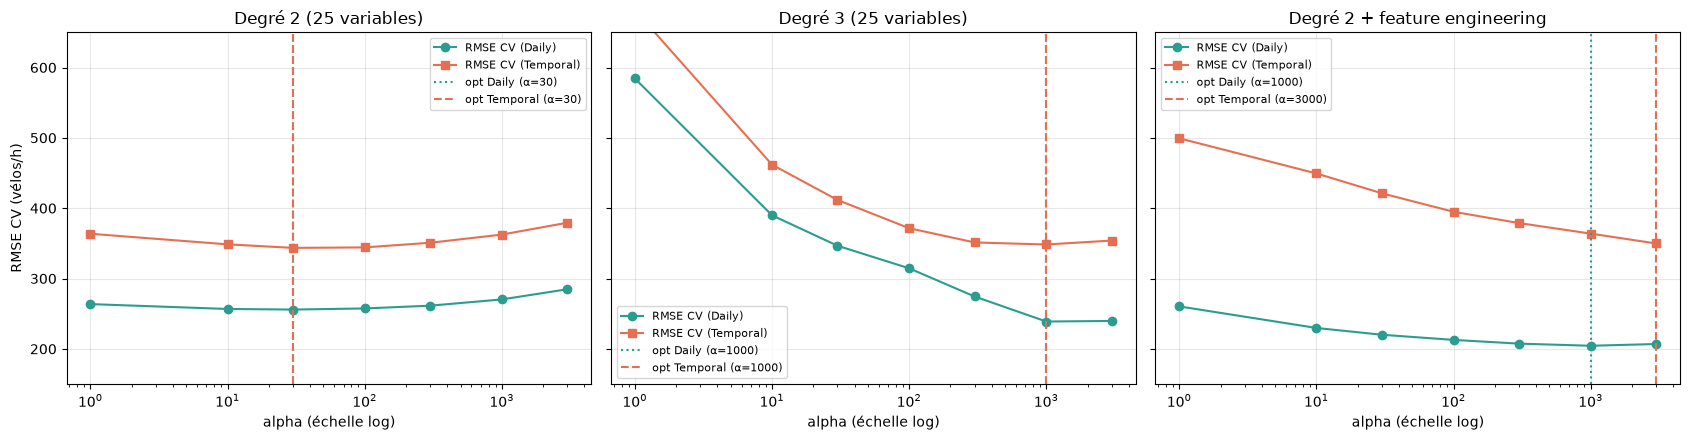

,alpha,Daily RMSE CV,Temporal RMSE CV
configuration,,,
Degré 2 (25 variables),30,255.9,343.6
Degré 3 (25 variables),1000,238.9,348.4
Degré 2 + feature engineering,1000,204.4,363.9


In [21]:
configurations = {
    "Degré 2 (25 variables)": (2, X_train, X_train_temporal),
    "Degré 3 (25 variables)": (3, X_train, X_train_temporal),
    "Degré 2 + feature engineering": (2, X_train_3, X_train_temporal_3),
}
alphas = [1, 10, 30, 100, 300, 1000, 3000]

courbes_ridge = []
for nom, (degre, X_d, X_t) in configurations.items():
    for alpha in alphas:
        modele = make_pipeline(PolynomialFeatures(degre, include_bias=False), VarianceThreshold(1e-6),
                               StandardScaler(), Ridge(alpha=alpha))
        s_d = cross_validate(modele, X_d, y_train, cv=splits,
                             scoring="neg_root_mean_squared_error", return_train_score=True, n_jobs=-1)
        s_t = cross_validate(modele, X_t, y_train_temporal, cv=splits_temporal,
                             scoring="neg_root_mean_squared_error", return_train_score=True, n_jobs=-1)
        courbes_ridge.append({
            "configuration": nom, "alpha": alpha,
            "Daily RMSE train": -s_d["train_score"].mean(), "Daily RMSE CV": -s_d["test_score"].mean(),
            "Temporal RMSE train": -s_t["train_score"].mean(), "Temporal RMSE CV": -s_t["test_score"].mean(),
        })
courbes_ridge = pd.DataFrame(courbes_ridge)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, nom in zip(axes, configurations):
    c = courbes_ridge[courbes_ridge["configuration"] == nom]
    meilleur_d = c.loc[c["Daily RMSE CV"].idxmin()]
    meilleur_t = c.loc[c["Temporal RMSE CV"].idxmin()]
    
    ax.plot(c["alpha"], c["Daily RMSE CV"], "o-", color="#2a9d8f", label="RMSE CV (Daily)")
    ax.plot(c["alpha"], c["Temporal RMSE CV"], "s-", color="#e76f51", label="RMSE CV (Temporal)")
    ax.axvline(meilleur_d["alpha"], color="#2a9d8f", linestyle=":", label=f"opt Daily (α={meilleur_d['alpha']:g})")
    ax.axvline(meilleur_t["alpha"], color="#e76f51", linestyle="--", label=f"opt Temporal (α={meilleur_t['alpha']:g})")
    ax.set(xscale="log", xlabel="alpha (échelle log)", title=nom, ylim=(150, 650))
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("RMSE CV (vélos/h)")
plt.tight_layout()
plt.show()

meilleurs_ridge = courbes_ridge.loc[courbes_ridge.groupby("configuration", sort=False)["Daily RMSE CV"].idxmin()]
display(meilleurs_ridge[["configuration", "alpha", "Daily RMSE CV", "Temporal RMSE CV"]].set_index("configuration").round(1))


Sur chaque graphique, quand α augmente, on passe du sur-apprentissage (α trop petit) au sous-apprentissage (α trop grand). En Temporal, l'effet est encore plus net : sans Ridge, les modèles polynomiaux explosent (plus de 10 000 vélos/h), et avec un α assez grand l'erreur redescend autour de 350 vélos/h.

| Configuration | Sans Ridge (Daily) | Sans Ridge (Temporal) | Meilleur Ridge (Daily) | Meilleur Ridge (Temporal) |
|---|---|---|---|---|
| Degré 2 (25 variables) | 287 | 28 727 | **256** (α = 30) | **344** (α = 30) |
| Degré 3 (25 variables) | ≈ 18 000 | ≈ 9 500 | **239** (α = 1 000) | **348** (α = 1 000) |
| Degré 2 + feature engineering | ≈ 14 000 | ≈ 25 000 | **204** (α = 1 000) | **350** (α = 3 000) |

La meilleure configuration est le **degré 2 sur les variables du feature engineering, avec Ridge (α = 1 000)** : elle combine les colonnes par heure et par tranche de température, leurs produits deux à deux, et le Ridge pour limiter le sur-apprentissage. α est choisi sur le Daily ; en Temporal le meilleur α est 3 000, mais l'écart est faible.

In [22]:
meilleur = meilleurs_ridge.loc[meilleurs_ridge["Daily RMSE CV"].idxmin()]
degre_5, X_5, X_5_t = configurations[meilleur["configuration"]]

evaluer(f"5. {meilleur['configuration']} + Ridge (alpha={meilleur['alpha']:g})",
        make_pipeline(PolynomialFeatures(degre_5, include_bias=False), VarianceThreshold(1e-6),
                      StandardScaler(), Ridge(alpha=meilleur["alpha"])),
        X_5)


,RMSE CV (Daily),R² CV (Daily),RMSE CV (Temporal),R² CV (Temporal)
Modèle,,,,
0. Moyenne (référence),644.8,-0.002,809.7,-0.528
1. Régression linéaire (25 variables),368.0,0.673,484.5,0.436
2a. Ridge (alpha=30),367.9,0.674,479.6,0.449
2b. Lasso (alpha=1),367.8,0.674,480.6,0.449
3. Feature engineering (89 variables),315.1,0.760,426.0,0.569
4. Régression polynomiale (degré 2),286.8,0.799,28727.3,-33861.353
5. Degré 2 + feature engineering + Ridge (alpha=1000),204.4,0.899,363.9,0.323


**Daily** : la RMSE CV passe de 287 à **204 vélos/h** et le R² de 0,80 à **0,90**. Le modèle explique 90 % des variations, et l'erreur a presque été divisée par deux depuis le modèle 1 (368).

**Temporal** : la RMSE CV redescend à **364 vélos/h**, contre 28 727 pour le polynôme sans Ridge.

On garde ce modèle 5 comme modèle final pour la régression linéaire.

## 9. Récapitulatif

,RMSE CV (Daily),R² CV (Daily),RMSE CV (Temporal),R² CV (Temporal)
Modèle,,,,
0. Moyenne (référence),644.8,-0.002,809.7,-0.528
1. Régression linéaire (25 variables),368.0,0.673,484.5,0.436
2a. Ridge (alpha=30),367.9,0.674,479.6,0.449
2b. Lasso (alpha=1),367.8,0.674,480.6,0.449
3. Feature engineering (89 variables),315.1,0.760,426.0,0.569
4. Régression polynomiale (degré 2),286.8,0.799,28727.3,-33861.353
5. Degré 2 + feature engineering + Ridge (alpha=1000),204.4,0.899,363.9,0.323


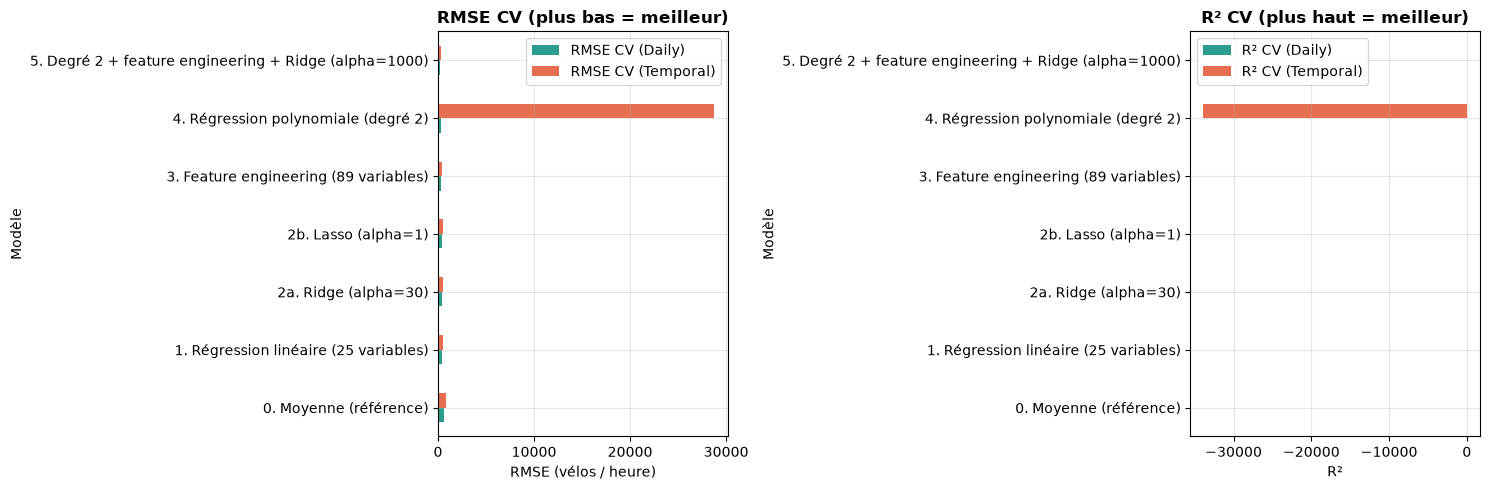

In [23]:
recap = pd.DataFrame(resultats).set_index("Modèle")
display(recap.round({"RMSE CV (Daily)": 1, "R² CV (Daily)": 3, "RMSE CV (Temporal)": 1, "R² CV (Temporal)": 3}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# RMSE
recap[["RMSE CV (Daily)", "RMSE CV (Temporal)"]].plot(kind="barh", ax=axes[0], color=["#2a9d8f", "#e76f51"])
axes[0].set_title("RMSE CV (plus bas = meilleur)", fontweight="bold")
axes[0].set_xlabel("RMSE (vélos / heure)")
axes[0].grid(True, alpha=0.3)

# R²
recap[["R² CV (Daily)", "R² CV (Temporal)"]].plot(kind="barh", ax=axes[1], color=["#2a9d8f", "#e76f51"])
axes[1].set_title("R² CV (plus haut = meilleur)", fontweight="bold")
axes[1].set_xlabel("R²")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Résumé des étapes

| Étape | RMSE CV (Daily) | R² CV (Daily) | RMSE CV (Temporal) | R² CV (Temporal) | Commentaire |
|---|---|---|---|---|---|
| 0. Moyenne (référence) | 644.8 | 0.00 | 809.7 | < 0 | Point de départ. |
| 1. Régression linéaire | 368.0 | 0.673 | 484.5 | 0.436 | Biais élevé, moins bon en temporel. |
| 2. Ridge / Lasso | 367.9 | 0.674 | 479.6 | 0.449 | Presque aucun effet en daily, petit gain en temporel. |
| 3. Feature engineering | 315.1 | 0.760 | 426.0 | 0.569 | Les colonnes par heure et par tranche de température réduisent le biais. |
| 4. Polynôme (degré 2) | 286.8 | 0.799 | 28 727 | < 0 | Mieux en daily, mais explose en temporel sans régularisation. |
| 5. Polynôme d2 + FE + Ridge | **204.4** | **0.899** | **363.9** | **0.323** | Meilleur modèle linéaire. |

**À retenir :**
- en Daily, avec les nouvelles variables et le polynôme de degré 2, la régression régularisée atteint un R² ≈ 0,90 ;
- en Temporal, les modèles sans régularisation s'effondrent vite : le Ridge est indispensable.

## 10. Évaluation finale sur les jeux de test

On évalue le modèle 5 une seule fois sur les jeux de test. La comparaison avec les autres modèles est faite dans `comparaison_finale.ipynb`.

- **Test Daily** : les 70 jours mis de côté (1 680 h) ;
- **Test Temporal** : les 10 semaines du 11/09 au 30/11/2018 (1 697 h). Chaque semaine est prédite par un modèle réentraîné sur toutes les données qui la précèdent (*walk-forward*).

In [24]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from decoupage import walk_forward

# Test daily
X_test_3 = feature_engineering(X_test)
assert list(X_test_3.columns) == list(X_train_3.columns)

modele_final_daily = make_pipeline(
    PolynomialFeatures(degre_5, include_bias=False),
    VarianceThreshold(1e-6),
    StandardScaler(),
    Ridge(alpha=meilleur["alpha"])
).fit(X_train_3, y_train)
pred_test_daily = modele_final_daily.predict(X_test_3)

reference_daily = make_pipeline(StandardScaler(), DummyRegressor(strategy="mean")).fit(X_train, y_train)
pred_ref_daily = reference_daily.predict(X_test)

# Test temporal : on réentraîne chaque semaine sur tout le passé
preds_wf = []
reels_wf = []
preds_wf_ref = []

for past, week in walk_forward(train_temporal, test_temporal):
    X_tr_past = feature_engineering(past[FEATURES])
    y_tr_past = past[CIBLE]
    X_te_week = feature_engineering(week[FEATURES])
    y_te_week = week[CIBLE]
    
    m_wf = make_pipeline(PolynomialFeatures(degre_5, include_bias=False), VarianceThreshold(1e-6),
                         StandardScaler(), Ridge(alpha=meilleur["alpha"]))
    m_wf.fit(X_tr_past, y_tr_past)
    preds_wf.extend(m_wf.predict(X_te_week))
    reels_wf.extend(y_te_week)
    
    ref_m = DummyRegressor(strategy="mean").fit(X_tr_past, y_tr_past)
    preds_wf_ref.extend(ref_m.predict(X_te_week))

preds_wf = np.array(preds_wf)
reels_wf = np.array(reels_wf)
preds_wf_ref = np.array(preds_wf_ref)

scores_test = pd.DataFrame([
    {"Protocole": "DAILY (70 jours)", "Modèle": "Référence (moyenne)", "RMSE": root_mean_squared_error(y_test, pred_ref_daily),
     "MAE": mean_absolute_error(y_test, pred_ref_daily), "R²": r2_score(y_test, pred_ref_daily)},
    {"Protocole": "DAILY (70 jours)", "Modèle": "Modèle final (Poly d2 + FE + Ridge)", "RMSE": root_mean_squared_error(y_test, pred_test_daily),
     "MAE": mean_absolute_error(y_test, pred_test_daily), "R²": r2_score(y_test, pred_test_daily)},
    {"Protocole": "TEMPORAL (Walk-Forward 10 sem)", "Modèle": "Référence (moyenne)", "RMSE": root_mean_squared_error(reels_wf, preds_wf_ref),
     "MAE": mean_absolute_error(reels_wf, preds_wf_ref), "R²": r2_score(reels_wf, preds_wf_ref)},
    {"Protocole": "TEMPORAL (Walk-Forward 10 sem)", "Modèle": "Modèle final (Poly d2 + FE + Ridge)", "RMSE": root_mean_squared_error(reels_wf, preds_wf),
     "MAE": mean_absolute_error(reels_wf, preds_wf), "R²": r2_score(reels_wf, preds_wf)},
]).set_index(["Protocole", "Modèle"])

display(scores_test.round({"RMSE": 1, "MAE": 1, "R²": 3}))

RMSE  \
Protocole                      Modèle                                       
DAILY (70 jours)               Référence (moyenne)                  632.5   
                               Modèle final (Poly d2 + FE + Ridge)  203.9   
TEMPORAL (Walk-Forward 10 sem) Référence (moyenne)                  628.2   
                               Modèle final (Poly d2 + FE + Ridge)  241.8   

                                                                      MAE  \
Protocole                      Modèle                                       
DAILY (70 jours)               Référence (moyenne)                  515.7   
                               Modèle final (Poly d2 + FE + Ridge)  127.2   
TEMPORAL (Walk-Forward 10 sem) Référence (moyenne)                  487.8   
                               Modèle final (Poly d2 + FE + Ridge)  161.1   

                                                                       R²  
Protocole                      Modèle                                      
DAILY (70 jours)               Référence (moyenne)                 -0.001  
                               Modèle final (Poly d2 + FE + Ridge)  0.896  
TEMPORAL (Walk-Forward 10 sem) Référence (moyenne)                 -0.100  
                               Modèle final (Poly d2 + FE + Ridge)  0.837

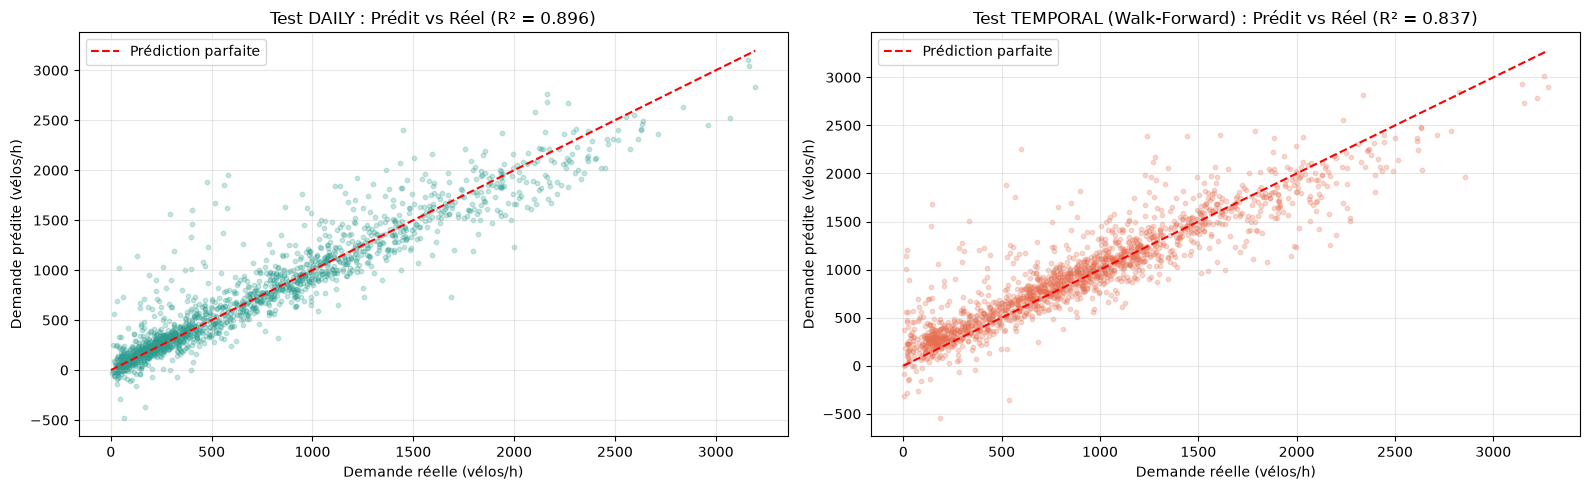

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Test daily
axes[0].scatter(y_test, pred_test_daily, alpha=0.25, s=10, color="#2a9d8f")
limite_d = max(y_test.max(), pred_test_daily.max())
axes[0].plot([0, limite_d], [0, limite_d], "r--", label="Prédiction parfaite")
axes[0].set(xlabel="Demande réelle (vélos/h)", ylabel="Demande prédite (vélos/h)",
            title=f"Test DAILY : Prédit vs Réel (R² = {r2_score(y_test, pred_test_daily):.3f})")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Test temporal
axes[1].scatter(reels_wf, preds_wf, alpha=0.25, s=10, color="#e76f51")
limite_t = max(reels_wf.max(), preds_wf.max())
axes[1].plot([0, limite_t], [0, limite_t], "r--", label="Prédiction parfaite")
axes[1].set(xlabel="Demande réelle (vélos/h)", ylabel="Demande prédite (vélos/h)",
            title=f"Test TEMPORAL (Walk-Forward) : Prédit vs Réel (R² = {r2_score(reels_wf, preds_wf):.3f})")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

### Résultats sur les jeux de test

| Protocole | Modèle | RMSE Test | MAE Test | R² Test |
|---|---|---|---|---|
| Daily (70 jours) | Référence (moyenne) | 632,5 | 515,7 | 0,000 |
| Daily (70 jours) | Modèle final (Poly d2 + FE + Ridge) | **203,9** | **127,2** | **0,896** |
| Temporal (walk-forward, 10 sem.) | Référence (moyenne) | 628,2 | 487,8 | −0,100 |
| Temporal (walk-forward, 10 sem.) | Modèle final (Poly d2 + FE + Ridge) | **241,8** | **161,1** | **0,837** |

- **Daily** : les scores de test (RMSE 204, R² 0,90) sont très proches de ceux de la cross-validation : le modèle ne sur-apprend pas.
- **Temporal** : en réentraînant le modèle chaque semaine, on obtient une RMSE de **242 vélos/h** et un R² de **0,84**. C'est mieux qu'en cross-validation (364), sans doute parce que chaque semaine de test est prédite avec un historique plus long.
- Ces résultats servent de point de comparaison pour les autres modèles dans `comparaison_finale.ipynb`.

## Conclusion

En partant d'une régression linéaire simple, on arrive sur les jeux de test à :
- **Daily** : R² = 0,896 (RMSE = 204 vélos/h, MAE = 127) ;
- **Temporal** : R² = 0,837 (RMSE = 242 vélos/h, MAE = 161).

Ce qui a fait progresser le modèle :
1. le **feature engineering** (colonnes par heure, tranches de température) ;
2. la **régression polynomiale**, qui croise les effets de la météo et de l'heure ;
3. la **régularisation Ridge**, qui limite le sur-apprentissage dû au grand nombre de combinaisons.